In [3]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from plots import *
from helper import *

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import OrdinalEncoder, TargetEncoder, OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from category_encoders import CountEncoder

In [5]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate, train_test_split

In [6]:
df_prices = pd.read_csv("C:/Users/redli/OneDrive/Desktop/classic ml tasks/regression/Hourly_Gasoline_Prices.csv")
df_fuel_st_info = pd.read_csv(r"C:\Users\redli\OneDrive\Desktop\classic ml tasks\regression\Fuel_Station_Information.csv")
df_full_eda = pd.merge(df_prices, df_fuel_st_info, how = "inner", on = "Id")
df_full_eda = df_full_eda.drop_duplicates()
df_full_eda.head(30)

,Id,isSelf,Price,Date,Fuel_station_manager,Petrol_company,Type,Station_name,City,Latitude,Longitudine
0,51169,1,1.943,2022-01-01 11:45:53,AURA PETROLSERVICE S.N.C. DI LANZA BRUNO & C.,Api-Ip,Autostradale,BAUDUCCHI OVEST,MONCALIERI,44.977978,7.700216
1,44566,1,1.725,2022-01-02 11:15:08,BOVE SOCIETA' A RESPONSABILITA' LIMITATA SEMPL...,Esso,Stradale,EASY,GALLIPOLI,40.059118,18.032323
2,44566,0,1.775,2022-01-02 11:15:08,BOVE SOCIETA' A RESPONSABILITA' LIMITATA SEMPL...,Esso,Stradale,EASY,GALLIPOLI,40.059118,18.032323
3,20026,1,1.729,2022-01-02 11:27:01,FIARDI TRADING - SOCIETA' A RESPONSABILITA' LI...,Api-Ip,Stradale,IP,CAMPOMARINO,41.938508,15.076976
4,12494,0,1.559,2022-01-02 12:07:25,BUSSINELLO S.R.L.,Pompe Bianche,Stradale,Impianto Verona Petroli - San Bonifacio,SAN BONIFACIO,45.386059,11.273766
5,12494,1,1.559,2022-01-02 12:07:25,BUSSINELLO S.R.L.,Pompe Bianche,Stradale,Impianto Verona Petroli - San Bonifacio,SAN BONIFACIO,45.386059,11.273766
6,37593,0,1.789,2022-01-02 12:36:25,CARBURANTI PALAZZO S.N.C.,Ies,Stradale,CARBURANTI PALAZZO SNC,BARANELLO,41.516827,14.594655
7,37593,1,1.789,2022-01-02 12:36:25,CARBURANTI PALAZZO S.N.C.,Ies,Stradale,CARBURANTI PALAZZO SNC,BARANELLO,41.516827,14.594655
8,50047,0,1.879,2022-01-02 14:20:37,DI BENEDETTO MARIA AGATA,SP Energia Siciliana,Stradale,stzione di servizio Di Benedetto Maria Agata,VENTIMIGLIA DI SICILIA,37.920051,13.565093
9,52185,0,1.800,2022-01-02 17:25:08,PIRA GIANPAOLO,Q8,Stradale,PIRA GIANPAOLO,BITTI,40.476894,9.382334


In [7]:
df_full_eda.to_csv('df_full_eda.csv', index=False)

In [8]:
from sklearn.linear_model import LinearRegression, LassoCV, RidgeCV, Lasso, Ridge, ElasticNet, ElasticNetCV
from sklearn.ensemble import GradientBoostingRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from xgboost import XGBRegressor, XGBRFRegressor
import optuna

In [9]:
'''from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml import Pipeline as pipiline
from pyspark.ml.feature import OneHotEncoder, StandardScaler, TargetEncoder, VectorAssembler, SQLTransformer
from pyspark.sql.window import Window
from pyspark.ml import Transformer'''

'from pyspark.sql import SparkSession\nfrom pyspark.sql import functions as F\nfrom pyspark.ml import Pipeline as pipiline\nfrom pyspark.ml.feature import OneHotEncoder, StandardScaler, TargetEncoder, VectorAssembler, SQLTransformer\nfrom pyspark.sql.window import Window\nfrom pyspark.ml import Transformer'

Вместо обычно randomforest использовался xgbrfregressor, так как его можно обучать на винде при помощи GPU

In [10]:
'''spark = SparkSession.builder.appName("HP_tunn").getOrCreate()
sampler_cols = ["Date", "Time", "Longitudine", "Latitude"]
spark = SparkSession.builder.appName("HP_tunn").getOrCreate()

sdf = spark.read.csv("df_full_eda.csv")

cols = list(df_full_eda.columns[:-1])
print(cols)

sql_transformer = SQLTransformer(statement= f"""
                SELECT *, 
                dayofyear(to_timestamp(Date)) AS day_of_year,
                hour(to_timestamp(Date)) * 60 + minute(to_timestamp(Date)) AS minute_of_year,
                array(coalscense(City, "Missing") AS City
                array(coalscense(Fuel_station_manager, 'MISSING')) AS Fuel_station_manager
                FROM __THIS__
""")

spark_pipline = pipiline(stages=[
    VectorAssembler(inputCols = sampler_cols, outputCol="scaler_features"),
    sql_transformer,
    StandardScaler(withMean = True, withStd = True, inputCol = "scaler_features"),
    OneHotEncoder(inputCols = ["Type"]),
    TargetEncoder(inputCols = ["Fuel_station_manager"]),
    TargetEncoder(inputCols = ["Petrol_company"]),
    VectorAssembler(inputCols = cols, outputCol="features"),
    LinearRegression()
]   
)'''

'spark = SparkSession.builder.appName("HP_tunn").getOrCreate()\nsampler_cols = ["Date", "Time", "Longitudine", "Latitude"]\nspark = SparkSession.builder.appName("HP_tunn").getOrCreate()\n\nsdf = spark.read.csv("df_full_eda.csv")\n\ncols = list(df_full_eda.columns[:-1])\nprint(cols)\n\nsql_transformer = SQLTransformer(statement= f"""\n                SELECT *, \n                dayofyear(to_timestamp(Date)) AS day_of_year,\n                hour(to_timestamp(Date)) * 60 + minute(to_timestamp(Date)) AS minute_of_year,\n                array(coalscense(City, "Missing") AS City\n                array(coalscense(Fuel_station_manager, \'MISSING\')) AS Fuel_station_manager\n                FROM __THIS__\n""")\n\nspark_pipline = pipiline(stages=[\n    VectorAssembler(inputCols = sampler_cols, outputCol="scaler_features"),\n    sql_transformer,\n    StandardScaler(withMean = True, withStd = True, inputCol = "scaler_features"),\n    OneHotEncoder(inputCols = ["Type"]),\n    TargetEncoder(inputCol

Я ЕГО СДЕЛАЛ!!! Отсюда убирать не буду, мне жалко( Клод сказал, что это все не правильно и это все не ускорит процесс, я замер, так и оказалось, он предложил убрать KNNImputer и избавиться от лямбды функции, это надеюсь поможет не обучать модель в течении часа

In [11]:
from funcs import datetime_processing_func,noise_processing_func

In [12]:
dt_proc = FunctionTransformer(datetime_processing_func)
noise_proc = FunctionTransformer(noise_processing_func)
base_line = Pipeline(
                         [ ("dt_proc", dt_proc),
                           ("noise_proc", noise_proc),
                           ("transformer", ColumnTransformer(
                                                              [
                                                                ("drop", "drop", ["Station_name"]),
                                                                ("city_encoder", CountEncoder(normalize=True, handle_unknown=0, handle_missing="value"), ["City"]),
                                                                ("manager_encoder", TargetEncoder(smooth='auto', cv=5), ["Fuel_station_manager"]), 
                                                                ("company_encoder", TargetEncoder(smooth='auto', cv=5), ["Petrol_company"]),
                                                                ("type_encoder", OneHotEncoder(drop = "first", sparse_output=False), ["Type"]),
                                                              ],
                                                              remainder = "passthrough", verbose_feature_names_out=False
                                                             )
                           ),
                           ("scaler", "passthrough"),
                           ("model", "passthrough")
                          ]
                         ) 
base_line.set_output(transform = "pandas")

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('dt_proc', ...), ('noise_proc', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function dat...0014C00B6CF60>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictio

In [13]:
models_w_tunned_params = {}

Для тюнинга параметров будет использована Optuna, она позволяет не перебирать напрямую все параметры, а выделять диапазон значений параметров, для которых скор наиболее высокий и останавливаться на них

In [14]:
from sklearn.base import clone
import optuna

In [15]:
def lasso(trial):
    return {"alpha" : trial.suggest_float("alpha", 0.01, 1, log=True)}
    
def ridge(trial):
    return {"alpha" : trial.suggest_float("alpha", 0.01, 1, log=True)}
    
def elasticnet(trial):
    return {"alpha" : trial.suggest_float("alpha", 0.01, 1, log=True), 
            "l1_ratio" : trial.suggest_float("l1_ratio", 0.05, 1.0, log=False),
           }
def rndforest(trial):
    return {"n_estimators" : trial.suggest_int("n_estimators", 100, 1000, step=100),
            "max_depth" : trial.suggest_int("max_depth", 3, 10),
            "min_child_weight" : trial.suggest_int("min_child_weight", 1, 5),
           }
def lgbm(trial):
    return {"learning_rate" : trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "n_estimators" : trial.suggest_int("n_estimators", 100, 1000, step=100),
            "min_child_samples" : trial.suggest_int("min_child_samples", 100, 1000, step=100),
            "num_leaves": trial.suggest_int("num_leaves", 15, 255, log=True),
           }
def xgboost(trial):
    return {"learning_rate" : trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "n_estimators" : trial.suggest_int("n_estimators", 100, 1000, step=100),
            "max_depth" : trial.suggest_int("max_depth", 3, 10), 
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
           }
def catboost(trial):
    return {"learning_rate" : trial.suggest_float("learning_rate", 0.01, 0.3, log=True), 
            "depth": trial.suggest_int("depth", 6, 10),
            "l2_leaf_reg": trial.suggest_int("l2_leaf_reg", 1, 30, log=True),
            "random_strength": trial.suggest_int("random_strength", 0, 5),
            "subsample" : trial.suggest_float("subsample", 0.5, 0.9, step = 0.1),
            "one_hot_max_size": trial.suggest_int("one_hot_max_size", 2, 30),
            "iterations" : trial.suggest_int("iterations", 500, 3000, step =100),
           }
param_grids = {
    "lgbm_model": lgbm,
    "xgboost_model": xgboost,
    "catboost_model": catboost,
}

In [16]:
models = {
"lgbm_model" : LGBMRegressor(),
"catboost_model" : CatBoostRegressor(loss_function="RMSE",
                          eval_metric="MAE", bootstrap_type="Bernoulli", verbose=0, task_type="GPU", devices="0",),
"xgboost_model" : XGBRegressor(device="cuda",)}

Все эти модели были в пайплайне на обучение, но от большинства я избавился, чтобы по несколько кругов не проверять, что самый лучшие метрики у лайт и катбуста

In [17]:
df_full_eda = df_full_eda.drop_duplicates().sort_values("Date").reset_index(drop=True)
split_idx = int(len(df_full_eda) * 0.8)
df_learning, df_check = df_full_eda.iloc[:split_idx], df_full_eda.iloc[split_idx:]

drop_cols = ["Price", "Id"]
X_train, y_train = df_learning.drop(drop_cols, axis = 1), df_learning["Price"]
X_test,  y_test  = df_check.drop(drop_cols, axis = 1),    df_check["Price"]


cv = TimeSeriesSplit(n_splits = 5)
folds = []

print(cv.split(X_train, y_train))
for step, (tr, vl) in enumerate(cv.split(X_train, y_train)):
    pipe = clone(base_line)
    X_tr = pipe.fit_transform(X_train.iloc[tr], y_train.iloc[tr])
    X_vl = pipe.transform(X_train.iloc[vl])
    folds.append([X_tr, y_train.iloc[tr].to_numpy(), X_vl, y_train.iloc[vl].to_numpy()])

<generator object TimeSeriesSplit._split at 0x0000014C00B90720>


In [18]:
folds[0][0].head()

,City,Fuel_station_manager,Petrol_company,Type_Stradale,isSelf,Date,Latitude,Longitudine,Time
0,0.000983,1.860447,1.838039,0.0,1,1,44.977978,7.700216,705
1,0.000413,1.860590,1.865230,1.0,1,2,40.059118,18.032323,675
2,0.000413,1.860939,1.865230,1.0,0,2,40.059118,18.032323,675
3,0.000291,1.860128,1.838364,1.0,1,2,41.938508,15.076976,687
4,0.000276,1.752685,1.806063,1.0,0,2,45.386059,11.273766,727


In [19]:
def objective(trial, model_name, model):
    params = param_grids[model_name](trial)
    scores = []
    for step, (X_tr, y_tr, X_vl, y_vl) in enumerate(folds):
        fold_model = clone(model).set_params(**params)
        fold_model.fit(X_tr, y_tr)
        scores.append(fold_model.score(X_vl, y_vl))
                     
        trial.report(np.mean(scores), step)
        if trial.should_prune():
            raise optuna.TrialPruned()
    return np.mean(scores)

studies = {}

for model_name in param_grids.keys():
    model = models[model_name]

    study = optuna.create_study(
        direction="maximize",
        study_name=model_name,
        sampler=optuna.samplers.TPESampler(seed=42),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1),
    )
    study.optimize(
        lambda trial: objective(trial, model_name, model),
        n_trials=30,
        timeout=1800,
    )
    studies[model_name] = study
    print(f"{model_name}: R² = {study.best_value:.4f}, {study.best_params}")

[I 2026-11-17 13:56:52,395] A new study created in memory with name: lgbm_model


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001863 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1596
[LightGBM] [Info] Number of data points in the train set: 319284, number of used features: 9
[LightGBM] [Info] Start training from score 1.834126
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004623 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1616
[LightGBM] [Info] Number of data points in the train set: 638564, number of used features: 9
[LightGBM] [Info] Start training from score 1.825438
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004319 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enoug

[I 2026-11-17 13:57:59,268] Trial 0 finished with value: -0.17657446948905425 and parameters: {'learning_rate': 0.03574712922600244, 'n_estimators': 1000, 'min_child_samples': 800, 'num_leaves': 81}. Best is trial 0 with value: -0.17657446948905425.


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001984 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1596
[LightGBM] [Info] Number of data points in the train set: 319284, number of used features: 9
[LightGBM] [Info] Start training from score 1.834126
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004553 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1616
[LightGBM] [Info] Number of data points in the train set: 638564, number of used features: 9
[LightGBM] [Info] Start training from score 1.825438
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004500 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enoug

[I 2026-11-17 13:58:17,151] Trial 1 finished with value: -0.2893818222778454 and parameters: {'learning_rate': 0.01700037298921102, 'n_estimators': 200, 'min_child_samples': 100, 'num_leaves': 174}. Best is trial 0 with value: -0.17657446948905425.


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001717 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1596
[LightGBM] [Info] Number of data points in the train set: 319284, number of used features: 9
[LightGBM] [Info] Start training from score 1.834126
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004653 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1616
[LightGBM] [Info] Number of data points in the train set: 638564, number of used features: 9
[LightGBM] [Info] Start training from score 1.825438
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004390 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enoug

... (56 outputs left out)

C:\Users\redli\AppData\Local\Programs\Python\Python314\Lib\site-packages\xgboost\core.py:569: UserWarning: [14:11:41] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)
[I 2026-11-17 14:12:18,519] Trial 0 finished with value: -0.1021055941433117 and parameters: {'learning_rate': 0.03574712922600244, 'n_estimators': 1000, 'max_depth': 8, 'reg_lambda': 0.24810409748678125}. Best is trial 0 with value: -0.1021055941433117.
[I 2026-11-17 14:12:23,162] Trial 1 finished with value: -0.3156297520898991 and parameters: {'learning_rate': 0.01700037298921102, 'n_est

xgboost_model: R² = -0.0792, {'learning_rate': 0.1604862886807379, 'n_estimators': 800, 'max_depth': 10, 'reg_lambda': 7.523025431383009}


Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
[I 2026-11-17 14:25:47,423] Trial 0 finished with value: -0.1456047219788271 and parameters: {'learning_rate': 0.03574712922600244, 'depth': 10, 'l2_leaf_reg': 10, 'random_strength': 3, 'subsample': 0.5, 'one_hot_max_size': 6, 'iterations': 600}. Best is trial 0 with value: -0.1456047219788271.
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
[I 2

catboost_model: R² = -0.0509, {'learning_rate': 0.2007540027957465, 'depth': 8, 'l2_leaf_reg': 7, 'random_strength': 3, 'subsample': 0.7, 'one_hot_max_size': 16, 'iterations': 2000}


In [37]:
studies_copy = studies.copy()

In [38]:
studies = studies_copy.copy()

In [52]:
for model_name, results in studies.items():
     print(f"{model_name}: R² = {results}")

lgbm_model: R² = <optuna.study.study.Study object at 0x0000014C7F55C2F0>
xgboost_model: R² = <optuna.study.study.Study object at 0x0000014C1A5C7C50>
catboost_model: R² = <optuna.study.study.Study object at 0x0000014C7FA73890>


In [40]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import r2_score, mean_absolute_percentage_error, root_mean_squared_error

Чтобы не проходить подбор параметров каждый раз по новой, засуну значения явно через дикты

In [57]:
result_models = models
result_models

{'lgbm_model': LGBMRegressor(learning_rate=0.17215943262452435, min_child_samples=300,
               n_estimators=1000, num_leaves=108),
 'catboost_model': CatBoostRegressor(bootstrap_type='Bernoulli', depth=8, devices='0', eval_metric='MAE', iterations=2000, l2_leaf_reg=7, learning_rate=0.2007540027957465, loss_function='RMSE', one_hot_max_size=16, random_strength=3, subsample=0.7, task_type='GPU', verbose=0),
 'xgboost_model': XGBRegressor(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device='cuda', early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1604862886807379, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=Non

In [58]:
list(folds[0][0].columns)

['City',
 'Fuel_station_manager',
 'Petrol_company',
 'Type_Stradale',
 'isSelf',
 'Date',
 'Latitude',
 'Longitudine',
 'Time']

In [59]:
target_mean = df_full_eda["Price"].mean()
result_metrics = {}
for name, model in result_models.items():
    model = clone(model)
    result_metrics[name] = {"R2" : [], "MAPE" : [], "RMSE": []}
    for fold in folds:
          model.fit(fold[0], fold[1])
          y_pred = model.predict(fold[2])
          result_metrics[name]["R2"].append(r2_score(fold[3], y_pred))
          result_metrics[name]["MAPE"].append(mean_absolute_percentage_error(fold[3], y_pred))
          result_metrics[name]["RMSE"].append(target_mean - root_mean_squared_error(fold[3], y_pred)/target_mean)
    result_metrics[name]["R2"] = np.mean(result_metrics[name]["R2"])
    result_metrics[name]["MAPE"] = np.mean(result_metrics[name]["MAPE"])
    result_metrics[name]["RMSE"] = np.mean(result_metrics[name]["RMSE"])
    print(f"{name}: "
          f"R2 {result_metrics[name]["R2"]:.4f} | "
          f"MAE {result_metrics[name]["MAPE"]:.4f} | "
          f"RMSE {result_metrics[name]["RMSE"]:.4f}" )

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001672 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1596
[LightGBM] [Info] Number of data points in the train set: 319284, number of used features: 9
[LightGBM] [Info] Start training from score 1.834126
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004759 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1616
[LightGBM] [Info] Number of data points in the train set: 638564, number of used features: 9
[LightGBM] [Info] Start training from score 1.825438
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005116 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enoug

Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU


catboost_model: R2 -0.0509 | MAE 0.0597 | RMSE 1.7536
xgboost_model: R2 -0.0792 | MAE 0.0599 | RMSE 1.7525


In [60]:
target_mean = df_full_eda["Price"].mean()
result_metrics = {}

pipe = clone(base_line)

X_train_prep = pipe.fit_transform(X_train, y_train)
X_test_prep = pipe.transform(X_test)

In [61]:
for name, model in result_models.items():
    model.fit(X_train_prep, y_train)
    y_pred = model.predict(X_test_prep)
    result_metrics[name] = [r2_score(y_test, y_pred), mean_absolute_percentage_error(y_test, y_pred), (target_mean - root_mean_squared_error(y_test, y_pred))/target_mean]
    print(f"{name}: "
          f"R2 {result_metrics[name][0]:.4f} | "
          f"MAE {result_metrics[name][1]:.4f} | "
          f"RMSE {result_metrics[name][2]:.4f}" )

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.011234 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1725
[LightGBM] [Info] Number of data points in the train set: 1915684, number of used features: 9
[LightGBM] [Info] Start training from score 1.865682
lgbm_model: R2 0.5531 | MAE 0.0393 | RMSE 0.9508


Default metric period is 5 because MAE is/are not implemented for GPU


catboost_model: R2 0.5337 | MAE 0.0407 | RMSE 0.9498
xgboost_model: R2 0.5694 | MAE 0.0382 | RMSE 0.9517


In [62]:
df_result_metrics = pd.DataFrame(result_metrics).set_axis(["R2", "MAPE", "RMSE"], axis=0).T
df_result_metrics

,R2,MAPE,RMSE
lgbm_model,0.553112,0.039276,0.950847
catboost_model,0.533694,0.040664,0.949791
xgboost_model,0.569364,0.038231,0.951749


<Axes: >

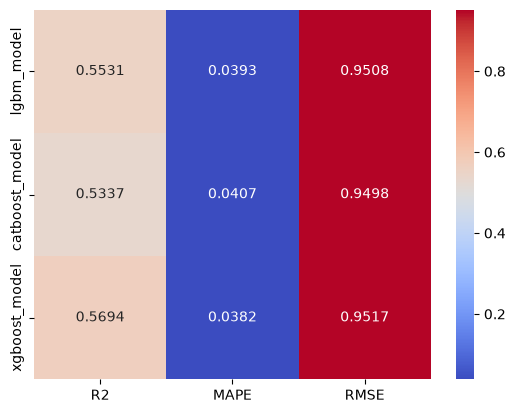

In [63]:
sns.heatmap(df_result_metrics, annot=True, cmap='coolwarm', fmt='.4f')

In [64]:
comparable_lgbm = {"MAPE" : 0.954100, "R2" : 0.836900, "RMSE": 0.927889}
diff_after_ht = pd.DataFrame()
for score in ["MAPE", "R2", "RMSE"]:
    diff_after_ht[score] = df_result_metrics[score] - comparable_lgbm[score]

<Axes: >

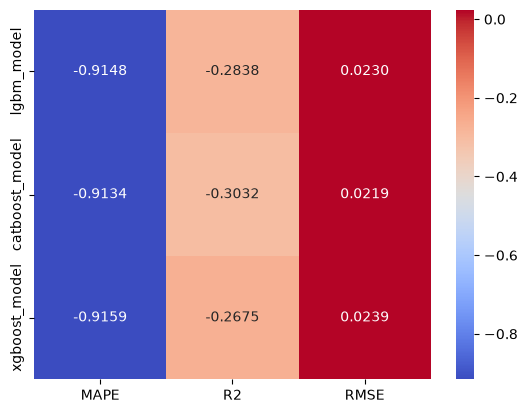

In [65]:
sns.heatmap(diff_after_ht, annot=True, cmap='coolwarm', fmt='.4f')

После тюнинга параметров показетели модели LightGBM выросли точность прогноща по MAE и RMSE выросла на 0.0322 и 0.0482 соотвественно, R^2 ошибки вырос на 0.1, чуть лучше себя показала XGBoost, он на сотые и тысячнык доли луше LighGBM

In [66]:
print(df_result_metrics.loc["xgboost_model"])
print(df_result_metrics.loc["lgbm_model"])
print(df_result_metrics.loc["catboost_model"])

R2      0.569364
MAPE    0.038231
RMSE    0.951749
Name: xgboost_model, dtype: float64
R2      0.553112
MAPE    0.039276
RMSE    0.950847
Name: lgbm_model, dtype: float64
R2      0.533694
MAPE    0.040664
RMSE    0.949791
Name: catboost_model, dtype: float64


In [67]:
result_models['xgboost_model'].get_params()

{'objective': 'reg:squarederror',
 'base_score': None,
 'booster': None,
 'callbacks': None,
 'colsample_bylevel': None,
 'colsample_bynode': None,
 'colsample_bytree': None,
 'device': 'cuda',
 'early_stopping_rounds': None,
 'enable_categorical': True,
 'eval_metric': None,
 'feature_types': None,
 'feature_weights': None,
 'gamma': None,
 'grow_policy': None,
 'importance_type': None,
 'interaction_constraints': None,
 'learning_rate': 0.1604862886807379,
 'max_bin': None,
 'max_cat_threshold': None,
 'max_cat_to_onehot': None,
 'max_delta_step': None,
 'max_depth': 10,
 'max_leaves': None,
 'min_child_weight': None,
 'missing': nan,
 'monotone_constraints': None,
 'multi_strategy': None,
 'n_estimators': 800,
 'n_jobs': None,
 'num_parallel_tree': None,
 'random_state': None,
 'reg_alpha': None,
 'reg_lambda': 7.523025431383009,
 'sampling_method': None,
 'scale_pos_weight': None,
 'subsample': None,
 'tree_method': None,
 'validate_parameters': None,
 'verbosity': None}

In [68]:
import joblib

In [69]:
bundle = {
        "lgbm_model": result_models["lgbm_model"],
        "pipeline": pipe,
        "xgboost": result_models["lgbm_model"],
        "metrics" : df_result_metrics.loc["lgbm_model"] 
}

In [ ]:
joblib.dump(bundle)